In [2]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Load the Fashion-MNIST dataset
(train_images, train_labels), (test_images, test_labels) = fashion_mnist.load_data()

In [4]:
class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

In [5]:
# Visualize random images from the dataset with labels as a grid using subplots
def visualize_random_images(images, labels, class_names):
    plt.figure(figsize=(10, 10))
    for i in range(25):
        idx = np.random.randint(0, len(images))
        plt.subplot(5, 5, i + 1)
        plt.xticks([])
        plt.yticks([])
        plt.grid(False)
        plt.imshow(images[idx], cmap=plt.cm.binary)
        plt.xlabel(class_names[labels[idx]], fontsize=10, fontweight='bold')
    plt.suptitle('Random Images from Fashion-MNIST', fontsize=16, fontweight='bold')
    plt.show()

# Plot the class distribution of images using a bar chart
def plot_class_distribution(labels, class_names):
    plt.figure(figsize=(10, 5))
    unique, counts = np.unique(labels, return_counts=True)
    sns.barplot(x=class_names, y=counts, palette='muted')
    plt.xlabel('Class', fontsize=12, fontweight='bold')
    plt.ylabel('Number of images', fontsize=12, fontweight='bold')
    plt.title('Class distribution of Fashion-MNIST dataset', fontsize=14, fontweight='bold')
    plt.xticks(rotation=45)
    plt.show()

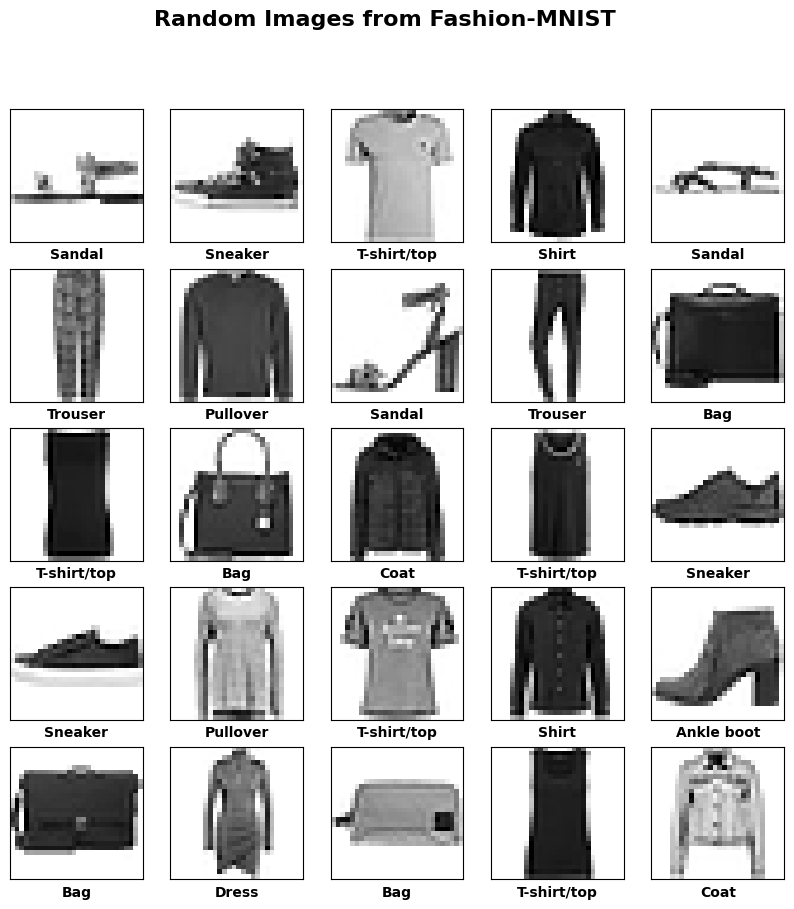

/var/folders/03/q36rn1_s5sb399lxs7gjqt500000gn/T/ipykernel_80243/3879337654.py:19: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_names, y=counts, palette='muted')


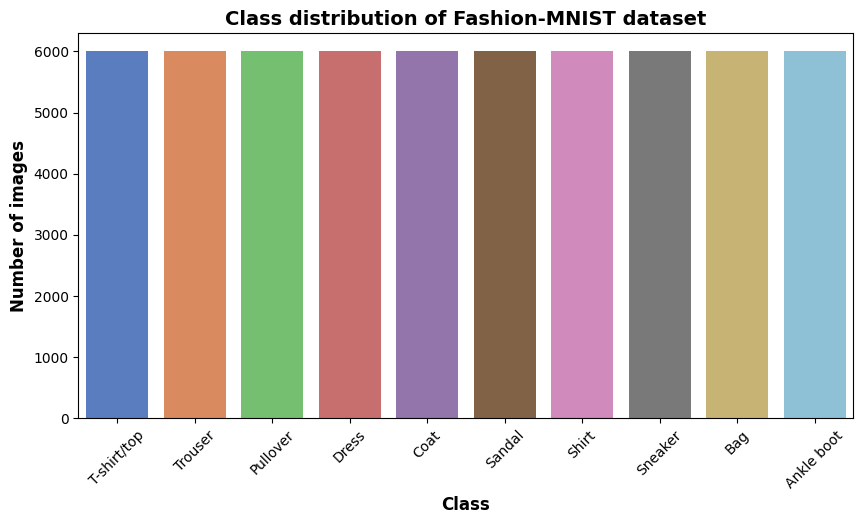

In [6]:
# Visualize random images
visualize_random_images(train_images, train_labels, class_names)

# Plot class distribution
plot_class_distribution(train_labels, class_names)

# Normalize the images
train_images = train_images / 255.0
test_images = test_images / 255.0

In [7]:
model = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile the model
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

# Train the model and store the training history
history = model.fit(train_images, train_labels, epochs=10, 
                    validation_data=(test_images, test_labels))

/Users/zulkifal/MS + Docs/Data Visualization/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.7465 - loss: 0.6863 - val_accuracy: 0.8553 - val_loss: 0.3892
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.8761 - loss: 0.3382 - val_accuracy: 0.8891 - val_loss: 0.3081
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.8975 - loss: 0.2779 - val_accuracy: 0.8927 - val_loss: 0.3005
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.9092 - loss: 0.2488 - val_accuracy: 0.8993 - val_loss: 0.2733
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 16ms/step - accuracy: 0.9199 - loss: 0.2161 - val_accuracy: 0.9070 - val_loss: 0.2577
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.9266 - loss: 0.1948 - val_accuracy: 0.9084 - val_loss: 0.2541
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.9340 - loss: 0.1776 - val_accuracy: 0.9067 - val_loss: 0.2667
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 33s 17ms/step - accuracy: 0.9377 -

In [8]:
def plot_learning_curves(history):
    plt.figure(figsize=(12, 4))
    
    # Plot training & validation loss values
    plt.subplot(1, 2, 1)
    plt.plot(history.history['loss'], label='Training Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Validation Loss', color='orange')
    plt.title('Model Loss', fontsize=14, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12, fontweight='bold')
    plt.ylabel('Loss', fontsize=12, fontweight='bold')
    plt.legend(loc='upper right')
    
    # Plot training & validation accuracy values
    plt.subplot(1, 2, 2)
    plt.plot(history.history['accuracy'], label='Training Accuracy', color='blue')
    plt.plot(history.history['val_accuracy'], label='Validation Accuracy', color='orange')
    plt.title('Model Accuracy', fontsize=14, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12, fontweight='bold')
    plt.ylabel('Accuracy', fontsize=12, fontweight='bold')
    plt.legend(loc='upper left')
    
    plt.suptitle('Learning Curves', fontsize=16, fontweight='bold')
    plt.show()

# Visualize the model architecture
def visualize_model_architecture(model):
    tf.keras.utils.plot_model(model, to_file='model_architecture.png', show_shapes=True, show_layer_names=True)
    img = plt.imread('model_architecture.png')
    plt.figure(figsize=(10, 10))
    plt.imshow(img)
    plt.axis('off')
    plt.title('Model Architecture', fontsize=16, fontweight='bold')
    plt.show()


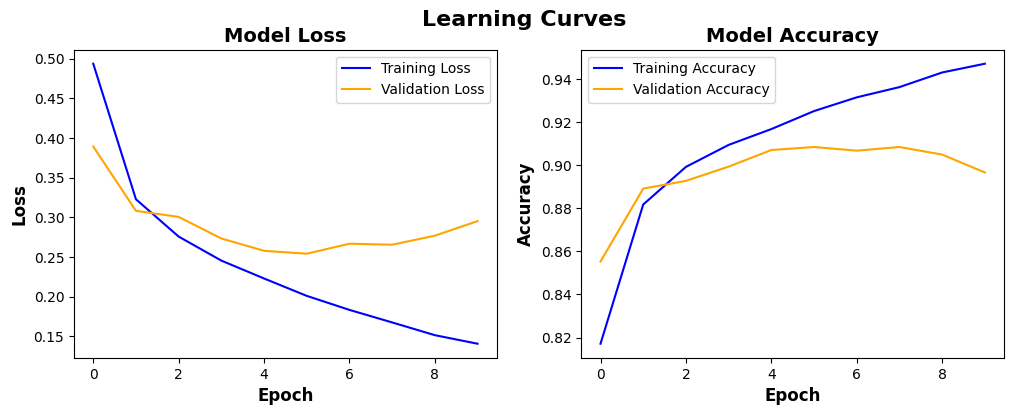

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


In [11]:
# Plot learning curves
plot_learning_curves(history)


# Predict the labels for the test set
test_predictions = model.predict(test_images)
test_predictions_labels = np.argmax(test_predictions, axis=1)

# Compute the confusion matrix
cm = confusion_matrix(test_labels, test_predictions_labels)

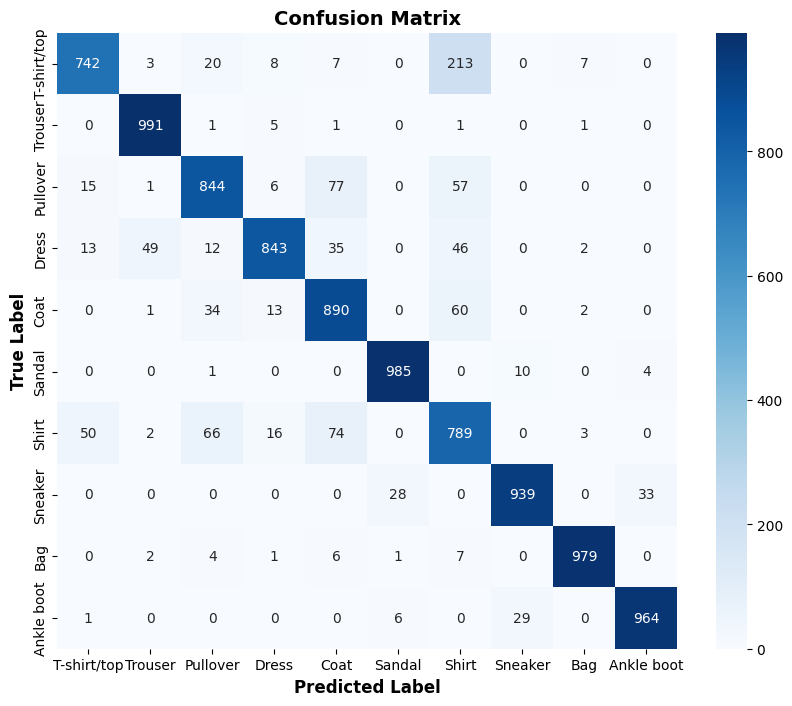

In [12]:
# Plot the confusion matrix using a heatmap
def plot_confusion_matrix(cm, class_names):
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
    plt.xlabel('Predicted Label', fontsize=12, fontweight='bold')
    plt.ylabel('True Label', fontsize=12, fontweight='bold')
    plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
    plt.show()

# Plot the confusion matrix
plot_confusion_matrix(cm, class_names)

# Normalize the images again (redundant step, but for clarity)
train_images_normalized = train_images / 255.0
test_images_normalized = test_images / 255.0

/Users/zulkifal/MS + Docs/Data Visualization/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 17ms/step - accuracy: 0.3731 - loss: 1.6448 - val_accuracy: 0.7058 - val_loss: 0.7639
Epoch 2/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 16ms/step - accuracy: 0.7214 - loss: 0.7429 - val_accuracy: 0.7325 - val_loss: 0.7129
Epoch 3/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.7440 - loss: 0.6780 - val_accuracy: 0.7460 - val_loss: 0.6778
Epoch 4/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.7582 - loss: 0.6417 - val_accuracy: 0.7639 - val_loss: 0.6292
Epoch 5/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 32s 17ms/step - accuracy: 0.7751 - loss: 0.5895 - val_accuracy: 0.7739 - val_loss: 0.5969
Epoch 6/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.7914 - loss: 0.5510 - val_accuracy: 0.7916 - val_loss: 0.5572
Epoch 7/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 31s 17ms/step - accuracy: 0.8021 - loss: 0.5271 - val_accuracy: 0.8039 - val_loss: 0.5322
Epoch 8/10
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 34s 18ms/step - accuracy: 0.8120 -

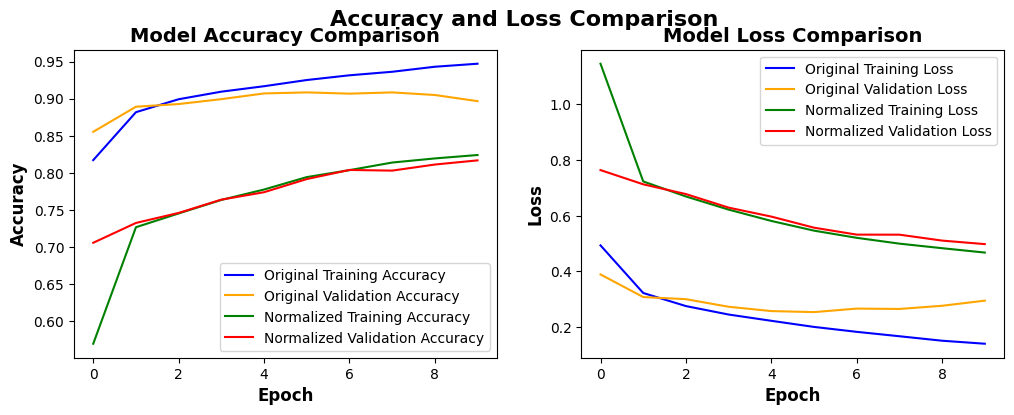

In [13]:
# Define the CNN model again
model_normalized = tf.keras.Sequential([
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

# Compile the model
model_normalized.compile(optimizer='adam',
                         loss='sparse_categorical_crossentropy',
                         metrics=['accuracy'])

# Train the model and store the training history
history_normalized = model_normalized.fit(train_images_normalized, train_labels, epochs=10, 
                                          validation_data=(test_images_normalized, test_labels))

# Compare the accuracy of the model before and after preprocessing
def compare_accuracies(history, history_normalized):
    plt.figure(figsize=(12, 4))
    
    # Plot training & validation accuracy values for both models
    plt.subplot(1, 2, 1)
    plt.plot(history.history['accuracy'], label='Original Training Accuracy', color='blue')
    plt.plot(history.history['val_accuracy'], label='Original Validation Accuracy', color='orange')
    plt.plot(history_normalized.history['accuracy'], label='Normalized Training Accuracy', color='green')
    plt.plot(history_normalized.history['val_accuracy'], label='Normalized Validation Accuracy', color='red')
    plt.title('Model Accuracy Comparison', fontsize=14, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12, fontweight='bold')
    plt.ylabel('Accuracy', fontsize=12, fontweight='bold')
    plt.legend(loc='lower right')
    
    # Plot training & validation loss values for both models
    plt.subplot(1, 2, 2)
    plt.plot(history.history['loss'], label='Original Training Loss', color='blue')
    plt.plot(history.history['val_loss'], label='Original Validation Loss', color='orange')
    plt.plot(history_normalized.history['loss'], label='Normalized Training Loss', color='green')
    plt.plot(history_normalized.history['val_loss'], label='Normalized Validation Loss', color='red')
    plt.title('Model Loss Comparison', fontsize=14, fontweight='bold')
    plt.xlabel('Epoch', fontsize=12, fontweight='bold')
    plt.ylabel('Loss', fontsize=12, fontweight='bold')
    plt.legend(loc='upper right')
    
    plt.suptitle('Accuracy and Loss Comparison', fontsize=16, fontweight='bold')
    plt.show()

# Compare accuracies
compare_accuracies(history, history_normalized)